# Perbandingan Akhir — kNN vs SVM vs Naive Bayes (PBL Harga Properti)

Notebook kontrol: menggabungkan hasil model terbaik dari ketiga metode klasifikasi.
Semua metode menggunakan **data hasil preprocessing yang sama** (`data_preprocessed.csv`)
dan **split yang sama** (80:20, stratified, random_state=42) — perbandingan fair.

Target: `kelas_harga` (Murah / Sedang / Mahal) — 15.000 data, 5 fitur ter-scaling.

## 1. Gabungkan Hasil Ketiga Metode

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

hasil = pd.concat([
    pd.read_csv('hasil_knn.csv'),
    pd.read_csv('hasil_svm.csv'),
    pd.read_csv('hasil_nb.csv'),
], ignore_index=True)

hasil.to_csv('hasil_perbandingan_klasifikasi.csv', index=False)
print('Tersimpan: hasil_perbandingan_klasifikasi.csv')
hasil.round(4)

Tersimpan: hasil_perbandingan_klasifikasi.csv


,Metode,Konfigurasi,Akurasi,Precision,Recall,F1
0,kNN,"k=13, metric=Euclidean (Minkowski p=2)",0.6763,0.6679,0.6767,0.6699
1,SVM,"kernel=rbf, C=1, gamma=1",0.6727,0.6625,0.6732,0.6616
2,Naive Bayes,BernoulliNB,0.6363,0.6191,0.6370,0.6175


## 2. Visualisasi Perbandingan

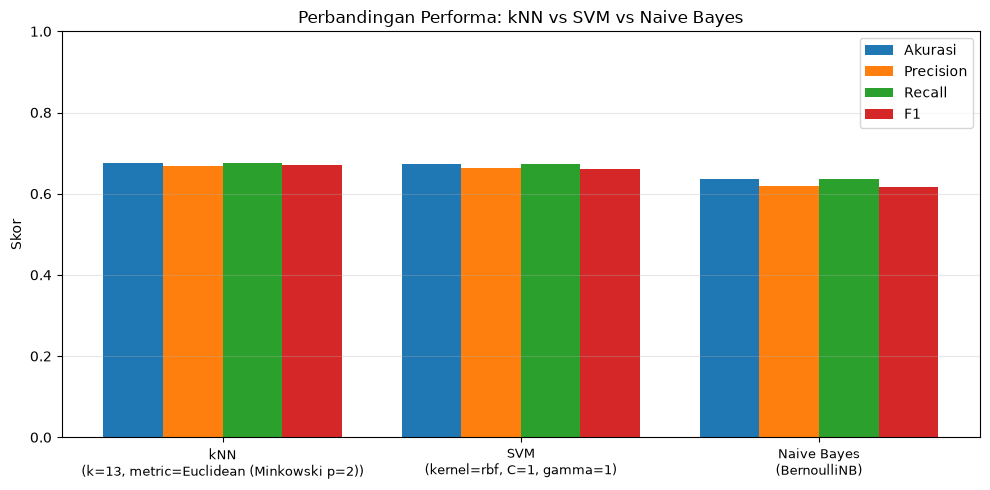

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
metrik = ['Akurasi', 'Precision', 'Recall', 'F1']
x = np.arange(len(hasil))
width = 0.2

for i, m in enumerate(metrik):
    ax.bar(x + i * width, hasil[m], width, label=m)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels([f"{r['Metode']}\n({r['Konfigurasi']})" for _, r in hasil.iterrows()], fontsize=9)
ax.set_ylabel('Skor')
ax.set_ylim(0, 1)
ax.set_title('Perbandingan Performa: kNN vs SVM vs Naive Bayes')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Confusion Matrix Ketiga Model (berdampingan)

Model terbaik tiap metode dilatih ulang dengan konfigurasi yang sama untuk divisualisasikan berdampingan.

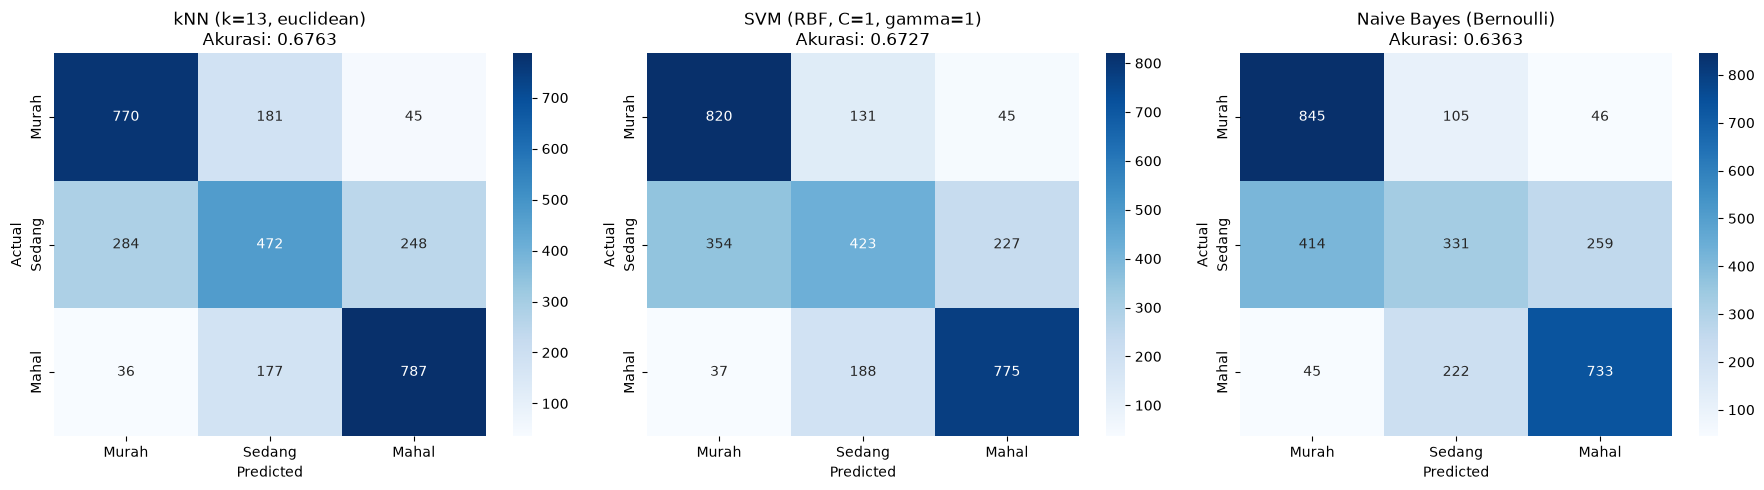

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import confusion_matrix, accuracy_score

df = pd.read_csv('data_preprocessed.csv')
X = df.drop(columns=['kelas_harga'])
y = df['kelas_harga']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

labels = ['Murah', 'Sedang', 'Mahal']

# kNN (k=13, euclidean)
knn = KNeighborsClassifier(n_neighbors=13)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

# SVM (rbf, C=1, gamma=1)
svm = SVC(kernel='rbf', C=1, gamma=1, random_state=42)
svm.fit(X_train, y_train)
pred_svm = svm.predict(X_test)

# Naive Bayes (Bernoulli, fitur di-binarisasi dengan median train)
median_train = X_train.median()
bnb = BernoulliNB()
bnb.fit((X_train > median_train).astype(int), y_train)
pred_nb = bnb.predict((X_test > median_train).astype(int))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, pred, nama in zip(axes,
                          [pred_knn, pred_svm, pred_nb],
                          ['kNN (k=13, euclidean)', 'SVM (RBF, C=1, gamma=1)', 'Naive Bayes (Bernoulli)']):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'{nama}\nAkurasi: {accuracy_score(y_test, pred):.4f}')
plt.tight_layout()
plt.show()

## 4. Kesimpulan Akhir

**Tabel perbandingan model terbaik tiap metode** (data & split identik, preprocessing identik):

| Metode | Konfigurasi Terbaik | Akurasi | Precision | Recall | F1 |
|---|---|---|---|---|---|
| **kNN** | k=13, euclidean | **0.6763** | **0.6679** | **0.6767** | **0.6699** |
| SVM | RBF, C=1, gamma=1 | 0.6727 | 0.6625 | 0.6732 | 0.6616 |
| Naive Bayes | Bernoulli (biner) | 0.6363 | 0.6191 | 0.6370 | 0.6175 |

**(1) Metode terbaik: kNN** (akurasi 0.6763), disusul SVM (0.6727) dengan selisih sangat tipis (±0,4%), lalu Naive Bayes (0.6363). kNN unggul karena pola harga properti bersifat **lokal** — properti dengan karakteristik serupa (luas, kamar, usia) memang cenderung berharga serupa, sehingga pendekatan "kemiripan tetangga" bekerja baik.

**(2) SVM setara kNN.** RBF mengungguli linear & polynomial, menandakan batas kelas yang non-linier. Setelah tuning (C=1, gamma=1) performanya nyaris menyamai kNN. Kelebihan SVM: prediksi data baru lebih cepat (hanya bergantung pada support vector) dan lebih hemat memori dibanding kNN yang harus menyimpan seluruh data training.

**(3) Naive Bayes paling rendah** namun tercepat. Penyebabnya adalah asumsi **independensi antar fitur** yang dilanggar data properti (luas, jumlah kamar, dan harga jelas berkorelasi), ditambah asumsi distribusi yang tidak terpenuhi. Bernoulli mengalahkan Gaussian karena fitur kontinu properti tidak berdistribusi normal per kelas.

**(4) Benang merah ketiga metode:** kelas **Sedang** selalu paling sulit diklasifikasikan (recall 0.33–0.47), karena posisinya di antara Murah dan Mahal sehingga batasnya kabur. Kelas Murah & Mahal jauh lebih mudah. Ini mengindikasikan bahwa pembagian kelas berbasis kuantil harga menghasilkan kelas tengah yang secara alami ambigu.

**(5) Dibandingkan hasil clustering (UTS):** tugas clustering sebelumnya menemukan bahwa segmentasi properti tidak sepenuhnya rapi — konsisten dengan hasil klasifikasi ini di mana kelas tengah sulit dipisahkan. Klasifikasi terbimbing (dengan label) memberikan performa yang terukur (±0.68), sementara clustering tanpa label harus "menebak" segmennya sendiri.

**Rekomendasi praktis:** untuk kasus prediksi kategori harga properti ini, **kNN atau SVM RBF** layak dipakai (pilih SVM jika data akan terus bertambah besar dan kecepatan prediksi penting); Naive Bayes cocok hanya sebagai baseline cepat.